In [1]:
import numpy as np
import matplotlib.pyplot as plt
from stl import Mesh
import pc_centrelines.iterative_pathfinder_centreline as ipf
from pc_centrelines.geometry import rotate
from tqdm import tqdm

In [2]:
# read the mesh file and its adjacent triangles. 
mesh_data = Mesh.from_file("../data/1_straight_cyl/straight_cyl.stl")

In [3]:
def compare_analytical(n, msim):
    
    n_norm = n /  np.linalg.norm(n)
    
    A = ipf.section_area(1, n_norm)
    W = ipf.analytical_W(1, n_norm)
    A2= np.zeros(msim)
    W2 = np.zeros(msim)
    
    for m in tqdm(range(0, msim)):
        noise = np.random.normal(0, 0.1, 3)
        _,_,_, w2, a2, _ = ipf.mesh_intersect(mesh_data, noise, n_norm)
        
        A2 [m] = a2
        W2 [m] = np.linalg.norm(w2)
    return  A, np.mean(A2), np.std(A2), np.linalg.norm(W), np.mean(W2), np.std(W2)


In [4]:
msim = 20

In [5]:
# test the minimiser against the analytical solution for a cylinder of radius 1, in the x direction. 
test_normals = np.zeros((msim, 3))

test_normals[:, 0] = np.ones(msim)
test_normals[:, 1] = np.sin(np.exp(np.linspace(np.log(0.001), np.log(np.pi/2), msim)))

thetai = [elem[0] / np.linalg.norm(elem) for elem in test_normals]
test_outputs = [compare_analytical(n, msim) for n in test_normals]


100%|██████████| 20/20 [00:06<00:00,  3.22it/s]


In [6]:
results = np.array(test_outputs)

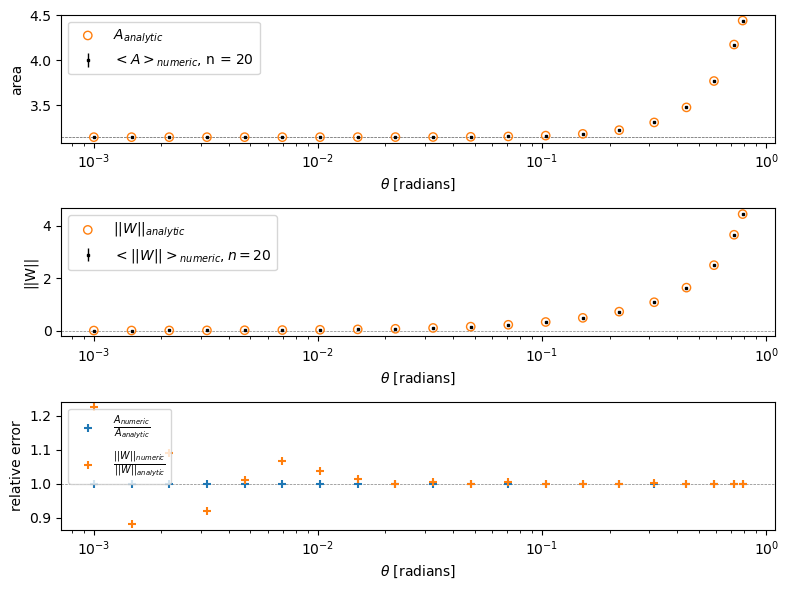

In [7]:
fig, axes = plt.subplots(3, 1, figsize = (8, 6))

axes[0].scatter(np.acos(thetai), results[:,0], label = "$A_{analytic}$", marker="o", color="None", edgecolor="C1")
axes[0].errorbar(np.acos(thetai), results[:,1], results[:,2] , label = f"$<A>_{{numeric}}$, n = {msim} ", marker = "s", markersize = 2, lw = 0, elinewidth=1, color ="k")

axes[0].set_ylabel("area")
axes[0].axhline(np.pi, lw = 0.5, ls="--", color ="grey", zorder = -1)

axes[1].scatter(np.acos(thetai), results[:,3], label = "$||W||_{analytic}$", marker="o", color="None", edgecolor="C1")
axes[1].errorbar(np.acos(thetai), results[:,4], results[:,5] , label = f"$<||W||>_{{numeric}}, n = {msim}$", marker = "s", markersize = 2, lw = 0, elinewidth=1, color ="k")

axes[1].set_ylabel("||W||")
axes[1].axhline(0, lw = 0.5, ls="--", color ="grey", zorder = -1)


axes[2].scatter(np.acos(thetai), results[:, 1] / results[:,0], label = "$\\frac{A_{numeric} }{ A_{analytic}}$", marker="+", color="C0")
axes[2].scatter(np.acos(thetai), results[:, 4] / results[:,3], label = "$\\frac{||W||_{numeric} }{ ||W||_{analytic}}$", marker="+", color="C1")
axes[2].axhline(1, ls="--", color ="grey", zorder = -1,  lw = 0.5)
axes[2].set_ylabel("relative error")
for ax in axes: 
    ax.legend()
    ax.set_xscale("log")
    ax.set_xlabel("$\\theta$ [radians]")


axes[0].axhline(np.pi, lw = 0.5, ls="--", color ="grey", zorder = -10)

plt.tight_layout()
#plt.savefig("../temp/figures/validation_code_WA.png", dpi = 300)
#plt.savefig("../temp/figures/validation_code_WA.pdf")
plt.show()
